# 🧬 CRISPR DeepHF — Notebook 1: Data Cleaning

**MLSN F26 · Group 2 · Tier 0 (Data Preparation)**

This notebook takes the raw DeepHF supplementary table and produces the **clean,
validated, split-labelled dataset** consumed by Notebook&nbsp;2 (Tier-1 baselines)
and, later, by the Tier-2 / Tier-3 deep-learning notebooks.

**Dataset:** Wang *et al.*, *"Optimized CRISPR guide RNA design for two
high-fidelity Cas9 variants by deep learning"*, *Nature Communications* **10**,
5286 (2019). <https://www.nature.com/articles/s41467-019-12281-8>

### What this notebook does
1. Load the raw Excel file and standardise the schema.
2. Clean strings, repair the known malformed PAM, and **assert** the biological
   contract ($N_{20}NGG$, efficiencies in $[0, 1]$).
3. EDA: per-variant summary statistics + the Fig. 2d efficiency distribution.
4. Preview the deep-learning sequence encodings (for Tiers 2–3).
5. Create the paper's **76.5 % / 8.5 % / 15 %** train/val/test split, freeze it
   into split-label columns, and save the cleaned CSVs to `data/processed/`.

> The heavy, reusable logic lives in the `crispr_deephf` package (`src/`); the
> cells below call it so this notebook stays readable for presenting.

In [3]:
# =============================================================================
# ENVIRONMENT SETUP  --  run ONE of the two blocks below
# =============================================================================

# -----------------------------------------------------------------------------
# [A] LOCAL (conda env: mlsn-group-2)  <-- active by default
# -----------------------------------------------------------------------------
import sys
from pathlib import Path

# Find the project root (the folder that contains `src/crispr_deephf`).
_here = Path.cwd()
ROOT = next(
    (p for p in (_here, *_here.parents) if (p / "src" / "crispr_deephf").is_dir()),
    _here,
)
sys.path.insert(0, str(ROOT / "src"))

# -----------------------------------------------------------------------------
# [B] GOOGLE COLAB  --  uncomment this whole block to run on Colab (GPU/faster)
# -----------------------------------------------------------------------------
# !pip install -q openpyxl pandas numpy scikit-learn matplotlib seaborn
# from google.colab import drive
# drive.mount('/content/drive')
# # Point ROOT at the shared project folder on your Drive:
# from pathlib import Path
# import sys
# ROOT = Path('/content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)')
# sys.path.insert(0, str(ROOT / 'src'))
# # ---- OR, instead of Drive, clone the GitHub repo into Colab: ----
# # !git clone https://github.com/<your-org>/mlsn-group-2.git
# # ROOT = Path('/content/mlsn-group-2'); sys.path.insert(0, str(ROOT / 'src'))

# -----------------------------------------------------------------------------
from crispr_deephf import config, data, features, models, plots

paths = config.get_paths(ROOT)
plots.set_style()
print(f"crispr_deephf v{config.__dict__.get('__version__', '')}".strip())
print("Project root :", paths.root)
print("Processed dir:", paths.data_processed)

crispr_deephf v
Project root : /Users/lloydtodaro/Desktop/MLSN_F26_Group2
Processed dir: /Users/lloydtodaro/Desktop/MLSN_F26_Group2/data/processed


## 1. Load the raw dataset & standardise the schema
We read `Sheet1` with `header=1` (row 0 is a title banner), drop the empty index
column, and rename to the project's canonical columns. A CSV backup of the raw
table is written to `data/raw/` for provenance.

In [4]:
raw_xlsx = data.find_raw_excel([paths.data_raw, paths.root])
print("Raw file:", raw_xlsx)

df = data.load_raw(raw_xlsx)

# Save a raw CSV backup (provenance).
df.to_csv(paths.data_raw / config.RAW_BACKUP_CSV, index=False)

print("Loaded shape:", df.shape)
df.head()

FileNotFoundError: Could not find '41467_2019_12281_MOESM3_ESM.xlsx'. Searched:
  /Users/lloydtodaro/Desktop/MLSN_F26_Group2/data/raw
  /Users/lloydtodaro/Desktop/MLSN_F26_Group2/data/raw/41467_2019_12281_MOESM3_ESM.xlsx
  /Users/lloydtodaro/Desktop/MLSN_F26_Group2
  /Users/lloydtodaro/Desktop/MLSN_F26_Group2/41467_2019_12281_MOESM3_ESM.xlsx

## 2. Clean strings, repair the PAM typo & validate sequences
Row `gRNA-26033` stores a corrupted 2-letter PAM (`GG`); it is repaired from the
21st nucleotide of the `21mer`. `clean_and_validate` then asserts every row obeys
the canonical CRISPR $N_{20}NGG$ rules and that all efficiencies lie in $[0, 1]$.

In [3]:
# Inspect the malformed PAM(s) before cleaning (for the presentation).
_pam = df["PAM"].astype(str).str.strip().str.upper()
bad = df[_pam.str.len() != 3]
print(f"Malformed PAM rows: {len(bad)}")
if len(bad):
    display(bad[["gRNA_ID", "gRNA_Seq", "PAM", "21mer"]])

df = data.clean_and_validate(df, strict=True)
print("All sequence & target integrity checks passed ✔")

Malformed PAM rows: 1


,gRNA_ID,gRNA_Seq,PAM,21mer
26032,gRNA-26033,ATTCACCTCGTTGGATTCAC,GG,ATTCACCTCGTTGGATTCACG


All sequence & target integrity checks passed ✔


## 3. Summary statistics & indel-efficiency distribution (Fig. 2d)
Because DeepHF only kept measurements with >100 deep-sequencing reads, each Cas9
variant has a slightly different count of valid rows (WT: 55,604 · eSpCas9: 58,617
· SpCas9-HF1: 56,888).

,count,missing_NaN,mean,median,std,min,25%,75%,max
WT_Efficiency,55604.0,4248,0.7265,0.8019,0.2176,0.0182,0.6088,0.8961,1.0
eSpCas9_Efficiency,58617.0,1235,0.3583,0.3414,0.1875,0.0071,0.2055,0.4961,1.0
SpCas9_HF1_Efficiency,56888.0,2964,0.4784,0.5006,0.2065,0.0085,0.3355,0.6356,1.0


C:\Users\Ovalt\AppData\Local\Temp\ipykernel_70236\934211710.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


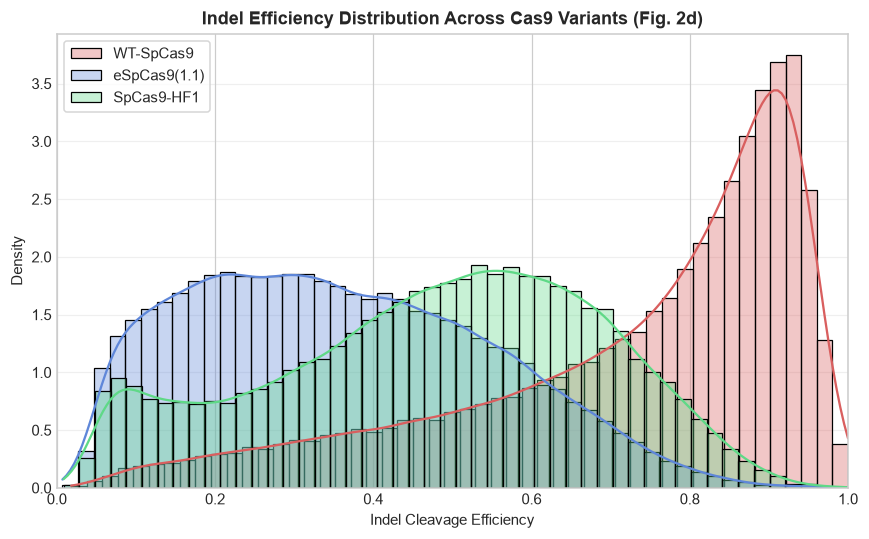

In [4]:
summary = data.summary_table(df)
display(summary.round(4))

fig = plots.plot_efficiency_distributions(df)
fig.savefig(paths.figures / "fig2d_efficiency_distributions.png", dpi=300)
fig.show()

## 4. Sequence encoding preview (for Tiers 2–3)
Each 21-mer becomes an integer token sequence (for `Embedding` layers) and a
$21 \times 4$ one-hot tensor (the paper's $x \in \mathbb{R}^{21\times4}$ for
1D-CNN layers). We only *preview* the shapes here; the deep-learning notebooks
reuse `features.encode_sequences`.

In [5]:
int_tokens, one_hot = features.encode_sequences(df["21mer"].head())
print("Integer tokens:", int_tokens.shape, int_tokens.dtype)
print("One-hot tensor:", one_hot.shape, one_hot.dtype)

Integer tokens: (5, 21) int64
One-hot tensor: (5, 21, 4) float32


## 5. Create the splits, freeze them & save the cleaned data
We follow the paper exactly: hold out **15 %** for test, then **10 % of the
remaining 85 %** for validation → **76.5 / 8.5 / 15** with `seed=42`. The split
is written into per-variant `*_split` columns so Notebook 2 reproduces the *same*
partition by simply reading the labels.

**Outputs (to `data/processed/`):**
- `deephf_clean_all.csv` — all 59,852 rows + split-label columns.
- `deephf_clean_multitask.csv` — the 53,937 rows valid for all three variants
  (for the Tier-3 multi-task model).

In [6]:
df = data.add_split_labels(df, seed=config.RANDOM_SEED)

# Report the frozen split sizes per variant.
for target, key in config.TARGET_KEYS.items():
    vc = df[f"{key}_split"].value_counts()
    total = int(vc.sum())
    print(f"{config.TARGET_LABELS[target]:<14} | total {total:>6,} | "
          f"train {vc.get('train', 0):>6,} | val {vc.get('val', 0):>5,} | "
          f"test {vc.get('test', 0):>5,}")

# Persist cleaned datasets.
all_path = paths.data_processed / config.CLEAN_ALL_CSV
mt_path = paths.data_processed / config.CLEAN_MULTITASK_CSV

df.to_csv(all_path, index=False)
df_multitask = df.dropna(subset=config.TARGET_COLS).reset_index(drop=True)
df_multitask.to_csv(mt_path, index=False)

print(f"\nSaved full cleaned dataset ({len(df):,} rows)  -> {all_path}")
print(f"Saved multi-task dataset  ({len(df_multitask):,} rows) -> {mt_path}")

WT-SpCas9      | total 55,604 | train 42,536 | val 4,727 | test 8,341
eSpCas9(1.1)   | total 58,617 | train 44,841 | val 4,983 | test 8,793
SpCas9-HF1     | total 56,888 | train 43,518 | val 4,836 | test 8,534

Saved full cleaned dataset (59,852 rows)  -> C:\conda_projects\mlsn-group-2\data\processed\deephf_clean_all.csv
Saved multi-task dataset  (53,937 rows) -> C:\conda_projects\mlsn-group-2\data\processed\deephf_clean_multitask.csv


`data/processed/deephf_clean_all.csv` is now the single source of truth. Open
**`02_tier1_baselines.ipynb`** to train and benchmark the Tier-1 gradient-boosted
tree baselines on this cleaned, split-labelled data.